# 07b — Rôles d'actifs : obligataire classé ou non, rémunération du cash

Comparaison courte, sur les **données locales** et avec la configuration du rapport mensuel, de quatre variantes :

| Variante | Obligataire (OBLI.PA) classé | Cash rémunéré par CSH2.PA |
| --- | :---: | :---: |
| A — historique | oui | non |
| B — défaut actuel | oui | oui |
| C — actions seules | non | oui |
| D — actions seules, cash à 0 | non | non |

Aucun paramètre n'est optimisé : il s'agit de documenter l'effet d'un choix de configuration. Aucun ordre n'est exécuté.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_prices
from src.metrics import compute_drawdown
from src.monthly_pipeline import UniverseConfig, load_config, run_monthly_pipeline
from src.universe import asset_roles, load_universe

prices = load_prices(PROJECT_ROOT / 'data' / 'processed' / 'universe_prices.csv')
base_config = load_config(PROJECT_ROOT / 'config' / 'strategy_params.yaml')
roles = asset_roles(load_universe(PROJECT_ROOT / 'config' / 'assets.yaml'))
print('Rôles :', roles)
print('Période :', prices.index.min().date(), '→', prices.index.max().date())

Rôles : {'CW8.PA': 'candidate', 'ESE.PA': 'candidate', 'WPEA.PA': 'candidate', 'PAEEM.PA': 'candidate', 'PUST.PA': 'candidate', 'PCEU.PA': 'candidate', 'PAASI.PA': 'candidate', 'GWT.PA': 'candidate', 'OBLI.PA': 'defensive', 'CSH2.PA': 'cash_proxy'}
Période : 2015-01-02 → 2026-09-23


In [2]:
variants = {
    'A — historique': UniverseConfig(defensive_as_candidates=True, use_cash_proxy_return=False),
    'B — défaut actuel': UniverseConfig(defensive_as_candidates=True, use_cash_proxy_return=True),
    'C — actions seules': UniverseConfig(defensive_as_candidates=False, use_cash_proxy_return=True),
    'D — actions seules, cash 0': UniverseConfig(defensive_as_candidates=False, use_cash_proxy_return=False),
}
rows, curves = [], {}
for name, universe_cfg in variants.items():
    result = run_monthly_pipeline(prices, replace(base_config, universe=universe_cfg), asset_roles=roles)
    report = result.report
    for label, strat, bt in (('Momentum', report.momentum_strategy, result.momentum_backtest),
                             ('Momentum + VT', report.volatility_targeted_strategy, result.vt_backtest)):
        rows.append({'variante': name, 'stratégie': label, 'CAGR': strat.cagr, 'volatilité': strat.annualized_volatility,
                     'Sharpe': strat.sharpe, 'max DD': strat.max_drawdown,
                     'allocation cible': ', '.join(f'{k} {v:.0%}' for k, v in strat.target_weights.items() if v > 1e-9)})
        curves[f'{name} | {label}'] = bt['Equity Curve']
bench = report.benchmark
rows.append({'variante': '—', 'stratégie': f'Buy & Hold {base_config.benchmark_ticker}', 'CAGR': bench.cagr,
             'volatilité': bench.annualized_volatility, 'Sharpe': bench.sharpe, 'max DD': bench.max_drawdown,
             'allocation cible': base_config.benchmark_ticker + ' 100%'})
table = pd.DataFrame(rows).set_index(['variante', 'stratégie'])
table.style.format({'CAGR': '{:.2%}', 'volatilité': '{:.2%}', 'Sharpe': '{:.2f}', 'max DD': '{:.2%}'})

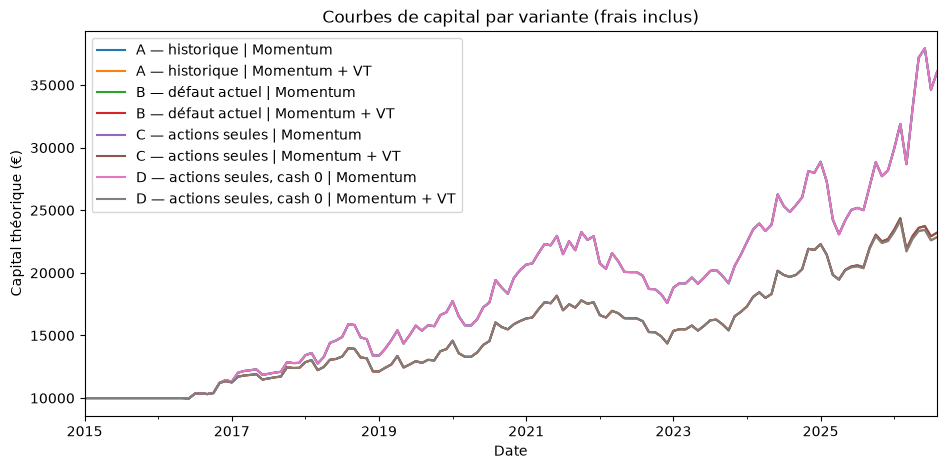

In [3]:
import matplotlib.pyplot as plt

ax = pd.DataFrame(curves).plot(figsize=(11, 5), title='Courbes de capital par variante (frais inclus)')
ax.set_ylabel('Capital théorique (€)')
plt.show()

## Lecture

- **CSH2.PA** n'a d'historique que depuis 2025-03 : avant, la poche cash reste rémunérée au taux fixe `backtest.cash_return` (0 %). L'effet du proxy est donc faible sur l'historique complet, mais il rend le rapport courant plus réaliste.
- Classer ou non l'obligataire change surtout le comportement en marché baissier (refuge obligataire vs cash).
- Le choix reste un **paramètre de configuration** (`config/strategy_params.yaml > universe`), à décider par l'investisseuse ; le défaut conserve le comportement historique pour l'obligataire.

### Constat au 2026-09-23 (signal du 2026-08-31)

- Les variantes A/C et B/D donnent des résultats **identiques** : sur tout l'historique, OBLI.PA n'est jamais le meilleur actif éligible (quand les actions échouent au filtre de tendance, l'obligataire échoue aussi ou a un momentum inférieur). Le switch n'a donc pas d'effet aujourd'hui, mais reste utile si l'univers obligataire s'élargit.
- Le proxy CSH2.PA améliore légèrement Momentum + VT (CAGR 7,34 % → 7,49 %) grâce à la rémunération du cash depuis 2025-03.
- Sur 2015-2026, le Momentum (CAGR 11,6 %, Sharpe 0,80, max DD −24,3 %) ne bat pas le Buy & Hold CW8.PA (CAGR 11,4 %, Sharpe 0,89, max DD −18,6 %) en rendement ajusté du risque.